Исследование и анализ датасета с Kaggle (https://www.kaggle.com/datasets/harishyadav0506/impact-of-social-media-on-life/data) с использованием pandas и Seaborn.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
#импорт необходимых библиотек

In [2]:
data_path = "data/Social_media_impact_on_life.csv" # исп. относительного пути для импорта
df = pd.read_csv(data_path)

In [3]:
df.head() # можно использовать df.tail()

,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,STU_2024004,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial


In [4]:
df.shape

(4500, 16)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Student_ID                   4500 non-null   str    
 1   Age                          4500 non-null   int64  
 2   Gender                       4500 non-null   str    
 3   Academic_Level               4500 non-null   str    
 4   Primary_Platform             4500 non-null   str    
 5   Daily_Usage_Hours            4500 non-null   float64
 6   Weekend_Extra_Hours          4500 non-null   float64
 7   Device_Type                  4500 non-null   str    
 8   Sleep_Duration_Hours         4500 non-null   float64
 9   Sleep_Quality_Score          4500 non-null   int64  
 10  Late_Night_Usage             4500 non-null   bool   
 11  Social_Comparison_Frequency  4500 non-null   str    
 12  Perceived_Stress_Score       4454 non-null   float64
 13  Mental_Health_Index          

In [6]:
df['Gender'].value_counts()

Gender
Female               2234
Male                 2051
Non-Binary            122
Prefer not to say      93
Name: count, dtype: int64

In [7]:
df[df['Academic_Performance_GPA'].isna()]['Academic_Level'].value_counts() 

Academic_Level
Undergraduate    56
High School      27
Postgraduate      2
Name: count, dtype: int64

In [8]:
df['Academic_Performance_GPA'].isna().groupby(df['Academic_Level']).mean() * 100 

Academic_Level
High School      1.828030
Postgraduate     0.813008
Undergraduate    2.016565
Name: Academic_Performance_GPA, dtype: float64

In [9]:
df.isna().sum()

Student_ID                      0
Age                             0
Gender                          0
Academic_Level                  0
Primary_Platform                0
Daily_Usage_Hours               0
Weekend_Extra_Hours             0
Device_Type                     0
Sleep_Duration_Hours            0
Sleep_Quality_Score             0
Late_Night_Usage                0
Social_Comparison_Frequency     0
Perceived_Stress_Score         46
Mental_Health_Index             0
Academic_Performance_GPA       85
Overall_Impact                  0
dtype: int64

Посмотрели, в каких группах и в каком процентном соотношении есть пропуски. Пропуски есть только в двух колонках: Perceived_Stress_Score (46, ~1%) и Academic_Performance_GPA (85, ~1,9%). Доля пропусков GPA почти одинакова во всех группах по уровню обучения (0,8–2%), поэтому пропуски, скорее всего, случайные, и строки с ними исключаются только там, где используется эта колонка. На странице датасета не описано, как проводился опрос, поэтому есть основания предполагать, что данные синтетические.

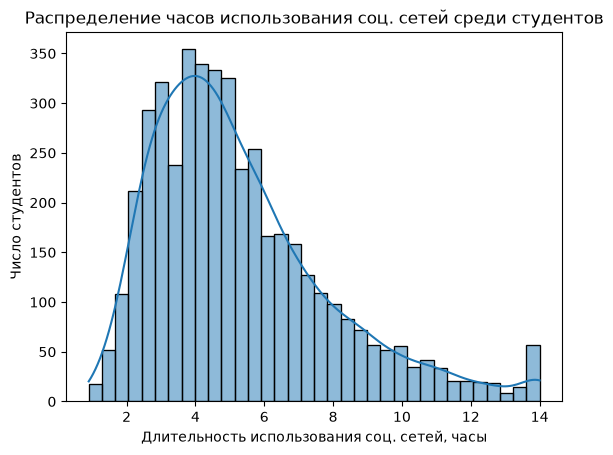

In [10]:
sns.histplot(df['Daily_Usage_Hours'], kde = True)
plt.title('Распределение часов использования соц. сетей среди студентов')
plt.ylabel('Число студентов')
plt.xlabel('Длительность использования соц. сетей, часы')
plt.show()

In [11]:
df['Daily_Usage_Hours'].agg(['mean', 'median'])

mean      5.295933
median    4.700000
Name: Daily_Usage_Hours, dtype: float64

In [12]:
df['Daily_Usage_Hours'].value_counts().sort_index().tail()

Daily_Usage_Hours
13.4     6
13.5     4
13.6     2
13.9     2
14.0    55
Name: count, dtype: int64

Среднее немного больше медианы, т.к справа есть 'Хвост'. На значении 14 (максимум шкалы) скопилось 55 студентов. Это характерно для синтетических данных.

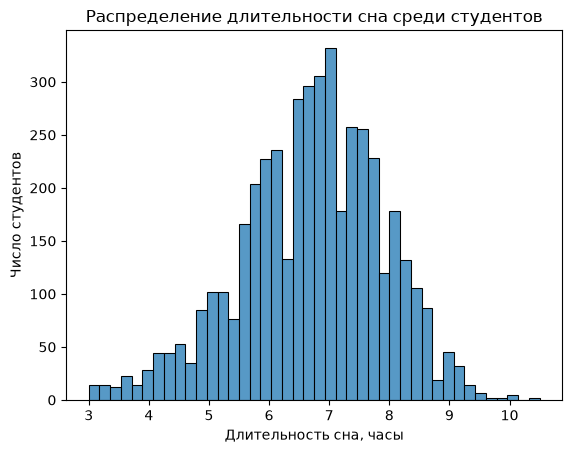

In [13]:
sns.histplot(df['Sleep_Duration_Hours'])
plt.title('Распределение длительности сна среди студентов')
plt.ylabel('Число студентов')
plt.xlabel('Длительность сна, часы')
plt.show()

In [14]:
df['Sleep_Duration_Hours'].agg(['mean','median']) 

mean      6.701333
median    6.800000
Name: Sleep_Duration_Hours, dtype: float64

Распределение симметричное, т.к нет "Хвостов".

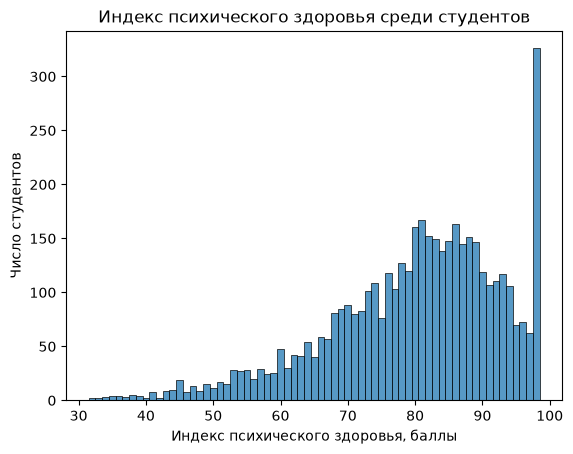

In [15]:
sns.histplot(df['Mental_Health_Index'], discrete = True)
plt.title('Индекс психического здоровья среди студентов')
plt.ylabel('Число студентов')
plt.xlabel('Индекс психического здоровья, баллы')
plt.show()

In [16]:
df['Mental_Health_Index'].agg(['mean','median'])

mean      79.873111
median    82.000000
Name: Mental_Health_Index, dtype: float64

In [17]:
df['Mental_Health_Index'].value_counts().sort_index().tail()

Mental_Health_Index
94    106
95     70
96     73
97     62
98    326
Name: count, dtype: int64

**Вывод**

Видим, что среднее (~79.9) немного ниже медианы (~82). У небольшой группы студентов индекс психического здоровья заметно ниже, чем у большинства и они тянут среднее вниз. На значении 98 (максимум шкалы) скопилось 326 студентов против 62 на 97. Такой пик характерен для обрезки значений при генерации данных.

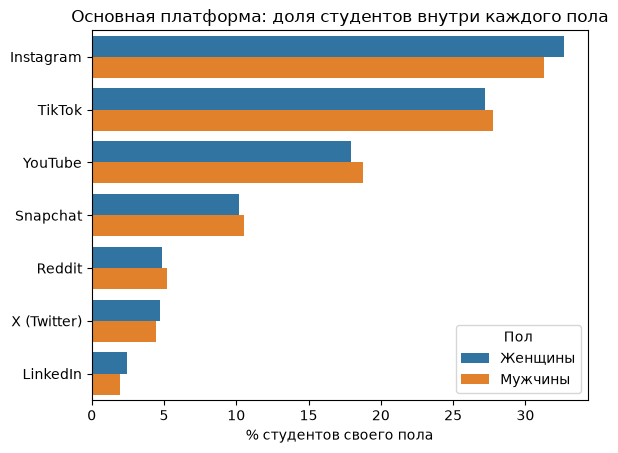

In [18]:
two_genders = df[df['Gender'].isin(['Female', 'Male'])]

pct = (two_genders.groupby('Gender')['Primary_Platform']
       .value_counts(normalize=True)
       .mul(100)
       .reset_index(name='percent'))

pct['Gender'] = pct['Gender'].map({'Female': 'Женщины', 'Male': 'Мужчины'})

order = df['Primary_Platform'].value_counts().index

sns.barplot(data=pct, y='Primary_Platform', x='percent', hue='Gender', order=order)
plt.title('Основная платформа: доля студентов внутри каждого пола')
plt.xlabel('% студентов своего пола')
plt.ylabel('')
plt.legend(title='Пол')
plt.show()

Instagram, TikTok, Youtube и Snapchat - самые популярные платформы среди студентов, далее идут Reddit и X (Twitter). Доли платформ внутри каждого пола почти одинаковы, то есть предпочтения от пола практически не зависят. Группы Non-Binary и Prefer not to say исключены из-за малого размера.

In [19]:
tenths = (df['Sleep_Duration_Hours'] * 10).round().astype(int) % 10
tenths.value_counts().sort_index()

Sleep_Duration_Hours
0    472
1    474
2    457
3    407
4    460
5    437
6    436
7    455
8    473
9    429
Name: count, dtype: int64

В реальных опросах люди называют круглые значения, поэтому среди ответов о сне преобладали бы десятые .0 и .5. Здесь все десятые доли от .0 до .9 встречаются примерно одинаково (по ~450 раз). Это ещё один признак того, что значения сгенерированы, а не получены от респондентов.

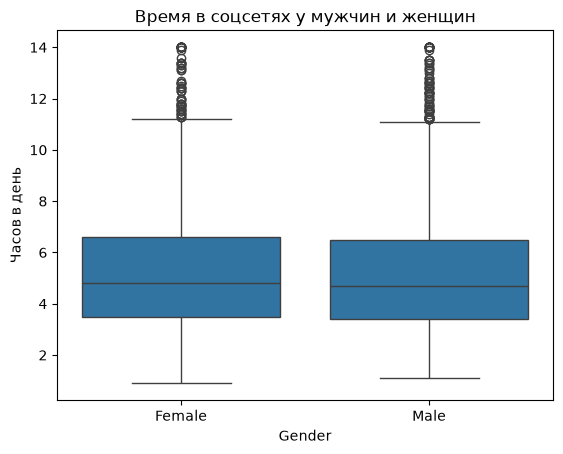

Gender
Female    4.8
Male      4.7
Name: Daily_Usage_Hours, dtype: float64

In [20]:
two_genders = df[df['Gender'].isin(['Female', 'Male'])]
sns.boxplot(data=two_genders, x='Gender', y='Daily_Usage_Hours')
plt.title('Время в соцсетях у мужчин и женщин')
plt.ylabel('Часов в день')
plt.show()
two_genders.groupby('Gender')['Daily_Usage_Hours'].median()

Медианное значение у мужчин и женщин практически совпадает, время, которое человек проводит в соц. сетях не зависит от пола.

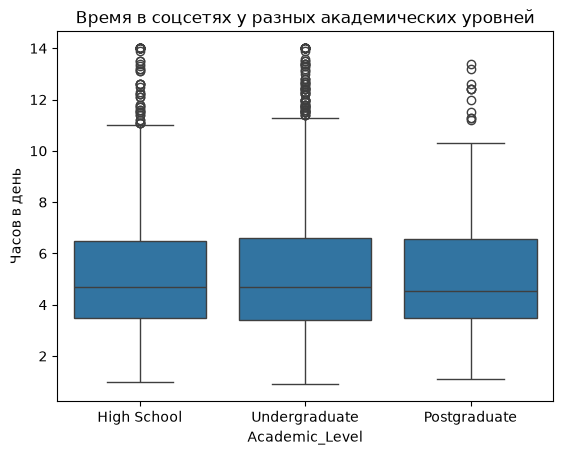

Academic_Level
High School      4.7
Postgraduate     4.5
Undergraduate    4.8
Name: Daily_Usage_Hours, dtype: float64

In [21]:
order=['High School', 'Undergraduate', 'Postgraduate']
sns.boxplot(data=two_genders, x='Academic_Level', y='Daily_Usage_Hours', order=order)
plt.title('Время в соцсетях у разных академических уровней')
plt.ylabel('Часов в день')
plt.show()
df.groupby('Academic_Level')['Daily_Usage_Hours'].median()

Медианное время в соцсетях почти не зависит от уровня обучения: у школьников - 4,7 ч в день, у бакалавров - 4,8 ч, у магистрантов - 4,5 ч. Разница между группами не превышает 0,3 часа (около 20 минут). Немного меньшее значение у магистрантов может быть случайным: эта группа самая маленькая (246 человек против 1.5к+ в остальных).

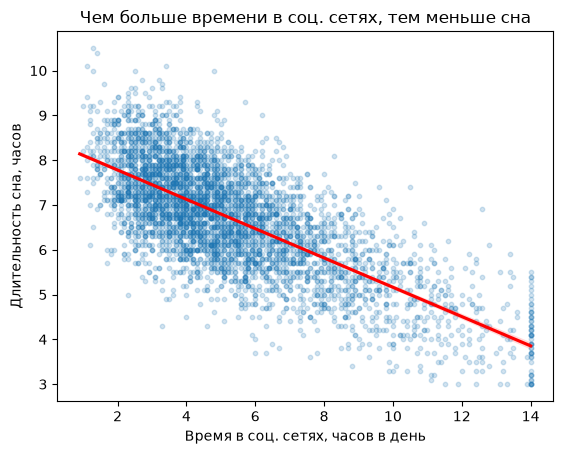

In [22]:
sns.regplot(data=df, x='Daily_Usage_Hours', y='Sleep_Duration_Hours', scatter_kws={'alpha': 0.2, 's': 10}, line_kws={'color': 'red'})
plt.title('Чем больше времени в соц. сетях, тем меньше сна')
plt.xlabel('Время в соц. сетях, часов в день')
plt.ylabel('Длительность сна, часов')
plt.show()

In [23]:
df['Daily_Usage_Hours'].corr(df['Sleep_Duration_Hours'])

np.float64(-0.7159026019117349)

Время в соцсетях и длительность сна связаны сильно и отрицательно (r = −0,72): студенты, которые проводят в соцсетях 2–3 часа в день, спят около 7,5-8 часов, а те, кто проводит 12-14 часов, - около 4–5 часов. Это корреляция, а не доказательство причины: возможно, студенты, которые плохо спят, просто дольше сидят в телефоне.

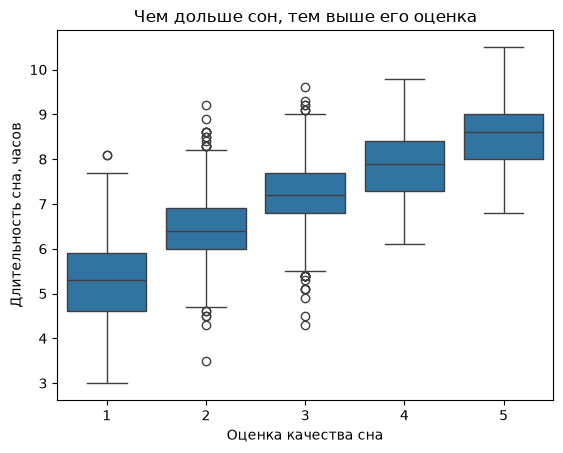

In [24]:
sns.boxplot(data=df, x='Sleep_Quality_Score', y='Sleep_Duration_Hours')
plt.title('Чем дольше сон, тем выше его оценка')
plt.xlabel('Оценка качества сна')
plt.ylabel('Длительность сна, часов')
plt.show()

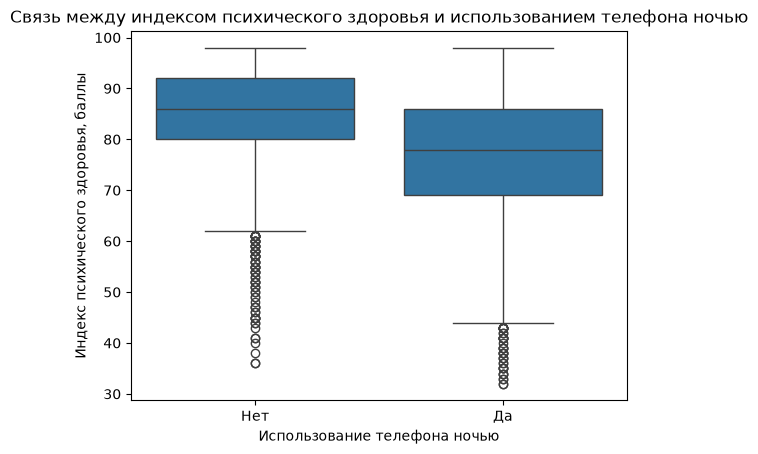

Late_Night_Usage
False    84.477371
True     76.641074
Name: Mental_Health_Index, dtype: float64

In [25]:
sns.boxplot(data=df, x='Late_Night_Usage', y='Mental_Health_Index')
plt.xticks([0, 1], ['Нет', 'Да'])
plt.title('Связь между индексом психического здоровья и использованием телефона ночью')
plt.xlabel('Использование телефона ночью')
plt.ylabel('Индекс психического здоровья, баллы')
plt.show()
df.groupby('Late_Night_Usage')['Mental_Health_Index'].mean()

У студентов, которые пользуются телефоном ночью, индекс психического здоровья в среднем ниже на ~8 баллов (76,6 против 84,5), медиана - около 78 против 86. Разброс у этой группы тоже больше: половина студентов попадает в диапазон примерно 69–86 баллов против 80–92 у тех, кто ночью телефоном не пользуется. При этом ящики заметно перекрываются, то есть ночное использование связано с более низким индексом, но не определяет его полностью. Это связь, а не причина: ночное использование может сопровождаться и большим временем в соцсетях, и меньшим сном, которые сами связаны с самочувствием.

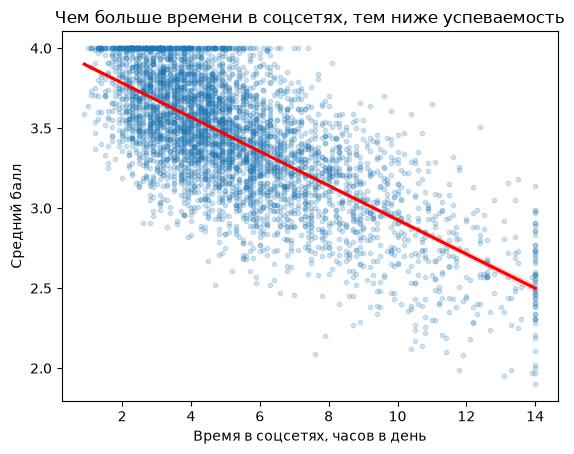

np.float64(-0.7100570097787984)

In [26]:
sns.regplot(data=df, x='Daily_Usage_Hours', y='Academic_Performance_GPA',
            scatter_kws={'alpha': 0.2, 's': 10}, line_kws={'color': 'red'})
plt.title('Чем больше времени в соцсетях, тем ниже успеваемость')
plt.xlabel('Время в соцсетях, часов в день')
plt.ylabel('Средний балл')
plt.show()
df['Academic_Performance_GPA'].corr(df['Daily_Usage_Hours'])

Время в соцсетях и успеваемость связаны сильно и отрицательно (r = -0,71): студенты, которые проводят в соцсетях 2-4 часа в день, чаще имеют GPA 3,5-4,0, а те, кто проводит 10 часов и больше, - около 2,0-3,0.

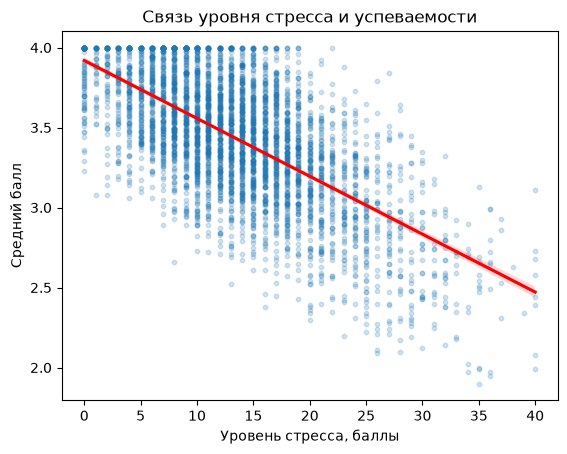

np.float64(-0.6509214121051609)

In [27]:
sns.regplot(data=df, x='Perceived_Stress_Score', y='Academic_Performance_GPA',
            scatter_kws={'alpha': 0.2, 's': 10}, line_kws={'color': 'red'})
plt.title('Связь уровня стресса и успеваемости')
plt.xlabel('Уровень стресса, баллы')
plt.ylabel('Средний балл')
plt.show()
df['Perceived_Stress_Score'].corr(df['Academic_Performance_GPA'])

Уровень стресса и успеваемость связаны отрицательно (r = -0,65, связь умеренная, близкая к сильной): у студентов с низким стрессом (0-10 баллов) GPA чаще всего 3,5-4,0, а при стрессе выше 30 баллов — около 2,5-3,0. Максимальный GPA 4,0 встречается почти только у студентов со стрессом до ~20 баллов.

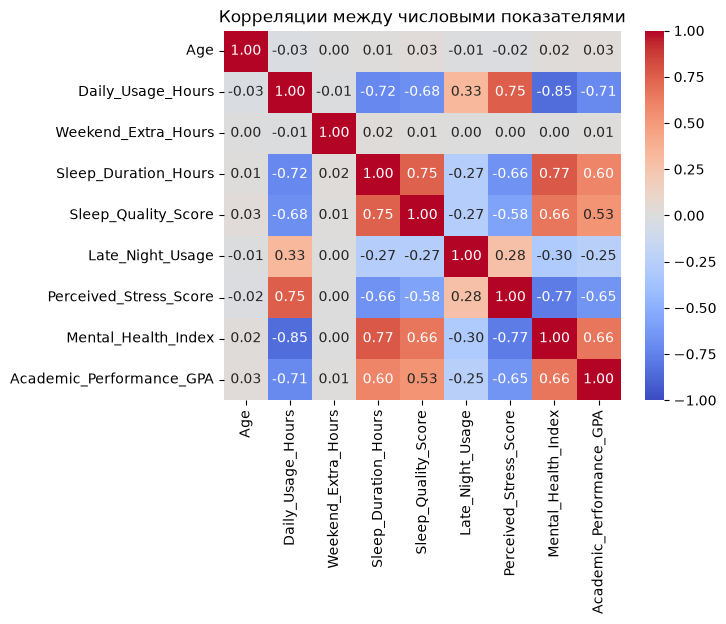

In [28]:
corr = df.select_dtypes(include=['number', 'bool']).corr()

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Корреляции между числовыми показателями')
plt.show()

Сильнее всего с успеваемостью связано время в соцсетях (r = −0,71), затем индекс психического здоровья (+0,66), стресс (−0,65) и длительность сна (+0,60). Однако эти показатели тесно связаны и между собой: время в соцсетях коррелирует с индексом психического здоровья (−0,85 - самая сильная связь в таблице), стрессом (+0,75) и сном (−0,72). Поэтому по корреляциям нельзя определить, какой из факторов действительно влияет на успеваемость.

In [29]:
df['Overall_Impact'].value_counts(normalize=True) * 100

Overall_Impact
Beneficial    81.800000
Neutral       14.533333
Negative       3.666667
Name: proportion, dtype: float64

In [30]:
df.groupby('Overall_Impact')[['Daily_Usage_Hours', 'Sleep_Duration_Hours', 'Perceived_Stress_Score']].median()

,Daily_Usage_Hours,Sleep_Duration_Hours,Perceived_Stress_Score
Overall_Impact,,,
Beneficial,4.2,7.0,11.0
Negative,12.4,4.1,31.0
Neutral,8.4,5.5,22.0


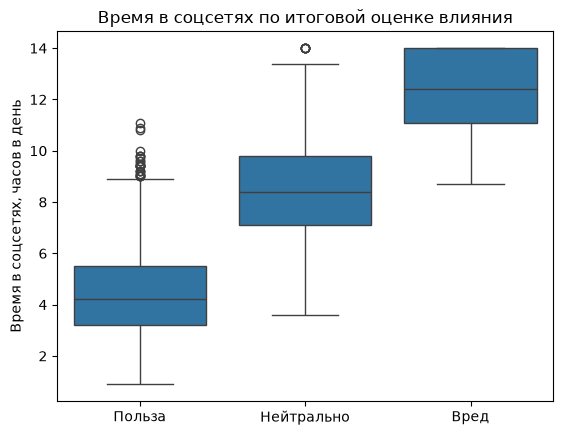

In [31]:
impact_order = ['Beneficial','Neutral','Negative']

sns.boxplot(data=df, x='Overall_Impact', y='Daily_Usage_Hours', order=impact_order)
plt.title('Время в соцсетях по итоговой оценке влияния')
plt.xlabel('')
plt.ylabel('Время в соцсетях, часов в день')
plt.xticks([0, 1, 2], ['Польза', 'Нейтрально', 'Вред'])
plt.show()

Группы по итоговой оценке влияния соцсетей сильно различаются: у студентов с оценкой «Польза» медианное время в соцсетях - 4,2 ч в день, сон - 7,0 ч, стресс - 11 баллов; у группы «Вред» - 12,4 ч, 4,1 ч и 31 балл соответственно; группа «Нейтрально» находится посередине. Средние 50% студентов разных групп по времени в соцсетях не перекрываются, то есть этот показатель почти разделяет группы.